In [ ]:
from google.colab import drive

# Montamos nuestro Drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
#Descomprimir el dataset
import os
import zipfile

os.chdir('/content/drive/MyDrive/DatasetCelulas/')

zip_path = 'Datasetv20.zip'

# ruta para los datos
extract_path = '/content/dataset'
#extracion del zip
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)


In [ ]:
import cv2
# Directorios
dir_dataset = '/content/dataset/Dataset'  # Directorio original
dir_datasetF = '/content/dataset_filtro'  # Directorio donde se guardaran las imágenes procesadas
os.makedirs(dir_datasetF, exist_ok=True)

# Aplicar filtros a las imagenes
def imagenFiltros(img, output_path):
    image = cv2.imread(img)
    # rgb
    imgGris = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Aplicar ecualizacion de histograma para mejorar el contraste
   # imgContraste = cv2.equalizeHist(imgGris)

    # Aplicar filtro gaussiano para suavizar
    imgGauss = cv2.GaussianBlur(imgGris, (5, 5), 0)

    # Guardar la imagen
    cv2.imwrite(output_path, imgGauss)

for fase in ['buenas', 'danadas']:
            #para las carpetas
            input_folder = os.path.join(dir_dataset,fase)
            output_folder = os.path.join(dir_datasetF,fase)

            os.makedirs(output_folder, exist_ok=True)
            #para las imagenes
            for img_name in os.listdir(input_folder):
                ruta_img = os.path.join(input_folder, img_name)
                rutaD_img = os.path.join(output_folder, img_name)
                imagenFiltros(ruta_img , rutaD_img)

print("Las imagenes se guardaron en", dir_datasetF)

Las imagenes se guardaron en /content/dataset_filtro


Found 894 images belonging to 2 classes.
Found 223 images belonging to 2 classes.


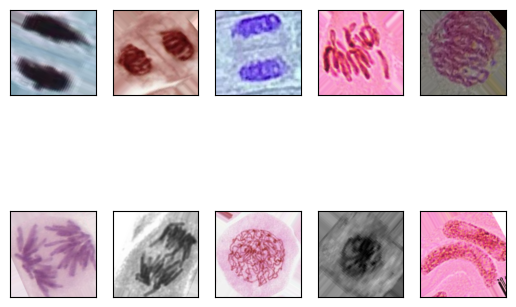

In [ ]:
#Generadores para sets de entrenamiento y pruebas
#Aumento de datos con ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

#Crear el dataset generador
datagen = ImageDataGenerator(
    rescale=1. / 255, #normaliza los pixeles 0 y 1
    rotation_range = 50, #rota la imagen hasta un 50%
    width_shift_range = 0.05, #desplazamiento horizontal
    height_shift_range = 0.05, #desplazamiento vertical
    shear_range = 10, #corte de eje 10 grados
   # zoom_range = [0.5, 1.5],
    horizontal_flip=True, #giro horizontal
    fill_mode='nearest', #rellena los pixeles
    validation_split=0.2 #20% para validacion
)

#Generadores para sets de entrenamiento y validacion
data_gen_entrenamiento = datagen.flow_from_directory('/content/dataset_filtro/', target_size=(224,224),
                                                     batch_size=32, shuffle=True, subset='training',class_mode='binary')
data_gen_validacion = datagen.flow_from_directory('/content/dataset_filtro/', target_size=(224,224),
                                                     batch_size=32, shuffle=True, subset='validation',class_mode='binary')

#Imprimir 10 imagenes del generador de validacion
for imagen, etiqueta in data_gen_validacion:
  for i in range(10):
    plt.subplot(2,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(imagen[i])
  break
plt.show()


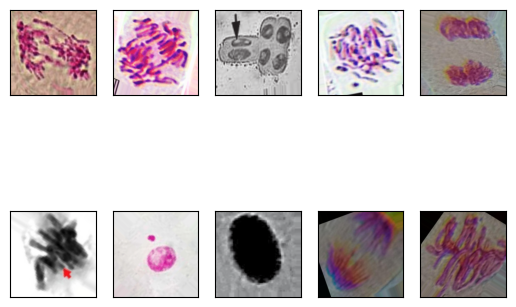

In [ ]:
#Imprimir 10 imagenes del generador de entrenamiento
for imagen, etiqueta in data_gen_entrenamiento:
  for i in range(10):
    plt.subplot(2,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(imagen[i])
  break
plt.show()


In [ ]:
!pip install efficientnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 3.0 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from efficientnet.tfkeras import EfficientNetB0

In [ ]:
from tensorflow.keras.regularizers import l2
# modelo preentrenado
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Congela las capas iniciales
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(), #reduce a un vector x canal
    layers.Dense(256, activation='relu', kernel_regularizer=l2(0.001)), # Regularizacion L2
   # layers.Dropout(0.3),  # para reducir el overfitting
    layers.Dense(1, activation='sigmoid')
])


16804768/16804768 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnet-b0 (Functional)    │ (None, 7, 7, 1280)     │     4,049,564 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,757 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,564 (15.45 MB)

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    data_gen_entrenamiento,
    epochs=70,
    validation_data=data_gen_validacion,
    callbacks=[early_stopping]
)

Epoch 1/70
28/28 ━━━━━━━━━━━━━━━━━━━━ 121s 4s/step - accuracy: 0.5278 - loss: 1.1239 - val_accuracy: 0.6278 - val_loss: 1.0272
Epoch 2/70
28/28 ━━━━━━━━━━━━━━━━━━━━ 132s 3s/step - accuracy: 0.7273 - loss: 0.9987 - val_accuracy: 0.8655 - val_loss: 0.9127
Epoch 3/70
28/28 ━━━━━━━━━━━━━━━━━━━━ 98s 4s/step - accuracy: 0.7849 - loss: 0.9202 - val_accuracy: 0.8834 - val_loss: 0.8424
Epoch 4/70
28/28 ━━━━━━━━━━━━━━━━━━━━ 100s 4s/step - accuracy: 0.7997 - loss: 0.8742 - val_accuracy: 0.9013 - val_loss: 0.8010
Epoch 5/70
28/28 ━━━━━━━━━━━━━━━━━━━━ 100s 4s/step - accuracy: 0.8477 - loss: 0.8257 - val_accuracy: 0.8744 - val_loss: 0.7683
Epoch 6/70
28/28 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.8520 - loss: 0.7827 - val_accuracy: 0.9148 - val_loss: 0.7287
Epoch 7/70
28/28 ━━━━━━━━━━━━━━━━━━━━ 101s 4s/step - accuracy: 0.8441 - loss: 0.7721 - val_accuracy: 0.9238 - val_loss: 0.6941
Epoch 8/70
28/28 ━━━━━━━━━━━━━━━━━━━━ 100s 4s/step - accuracy: 0.8553 - loss: 0.7391 - val_accuracy: 0.9283 - va

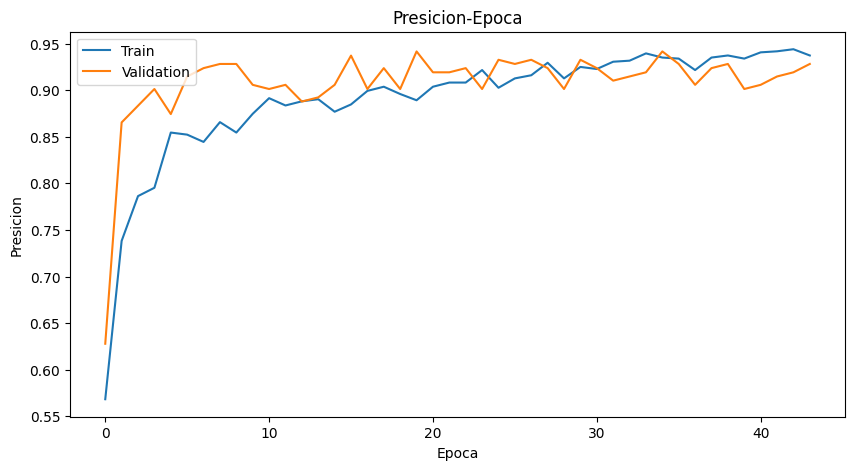

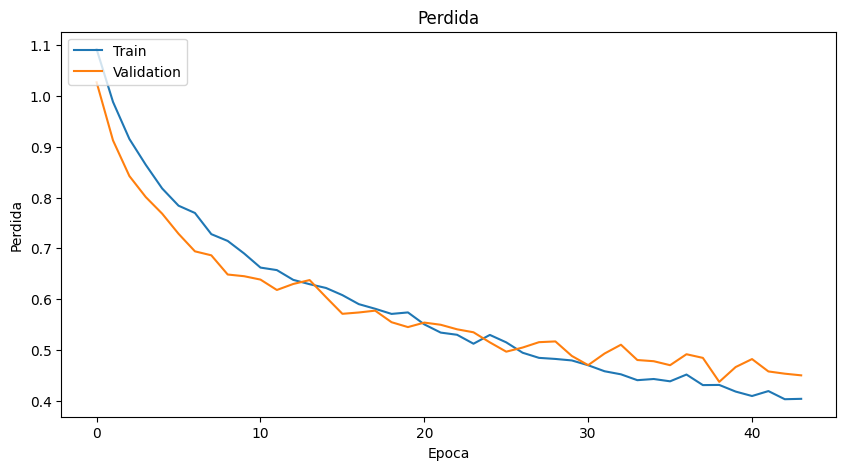

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Presicion-Epoca')
plt.ylabel('Presicion')
plt.xlabel('Epoca')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Perdida')
plt.ylabel('Perdida')
plt.xlabel('Epoca')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
class_indices = data_gen_validacion.class_indices
class_indices


{'buenas': 0, 'danadas': 1}

In [ ]:
print(f"Precisión del modelo en el conjunto de entrenamiento: {max(history.history['accuracy']):.4f}")
print(f"Precisión del modelo en el conjunto de validación: {max(history.history['val_accuracy']):.4f}")

Precisión del modelo en el conjunto de entrenamiento: 0.9441
Precisión del modelo en el conjunto de validación: 0.9417


In [ ]:
# evaluacion final
test_loss, test_acc = model.evaluate(data_gen_validacion)
print(f"Presicion: {test_acc}")
print(f"Perdida: {test_loss}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.9145 - loss: 0.4691
Presicion: 0.9192824959754944
Perdida: 0.45221856236457825


In [ ]:
model_path = '/content/drive/MyDrive/Modelos/Mitosisv2.keras'
model.save(model_path)


print(f"Modelo guardado en: {model_path}")

Modelo guardado en: /content/drive/MyDrive/Modelos/Mitosisv2.keras


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

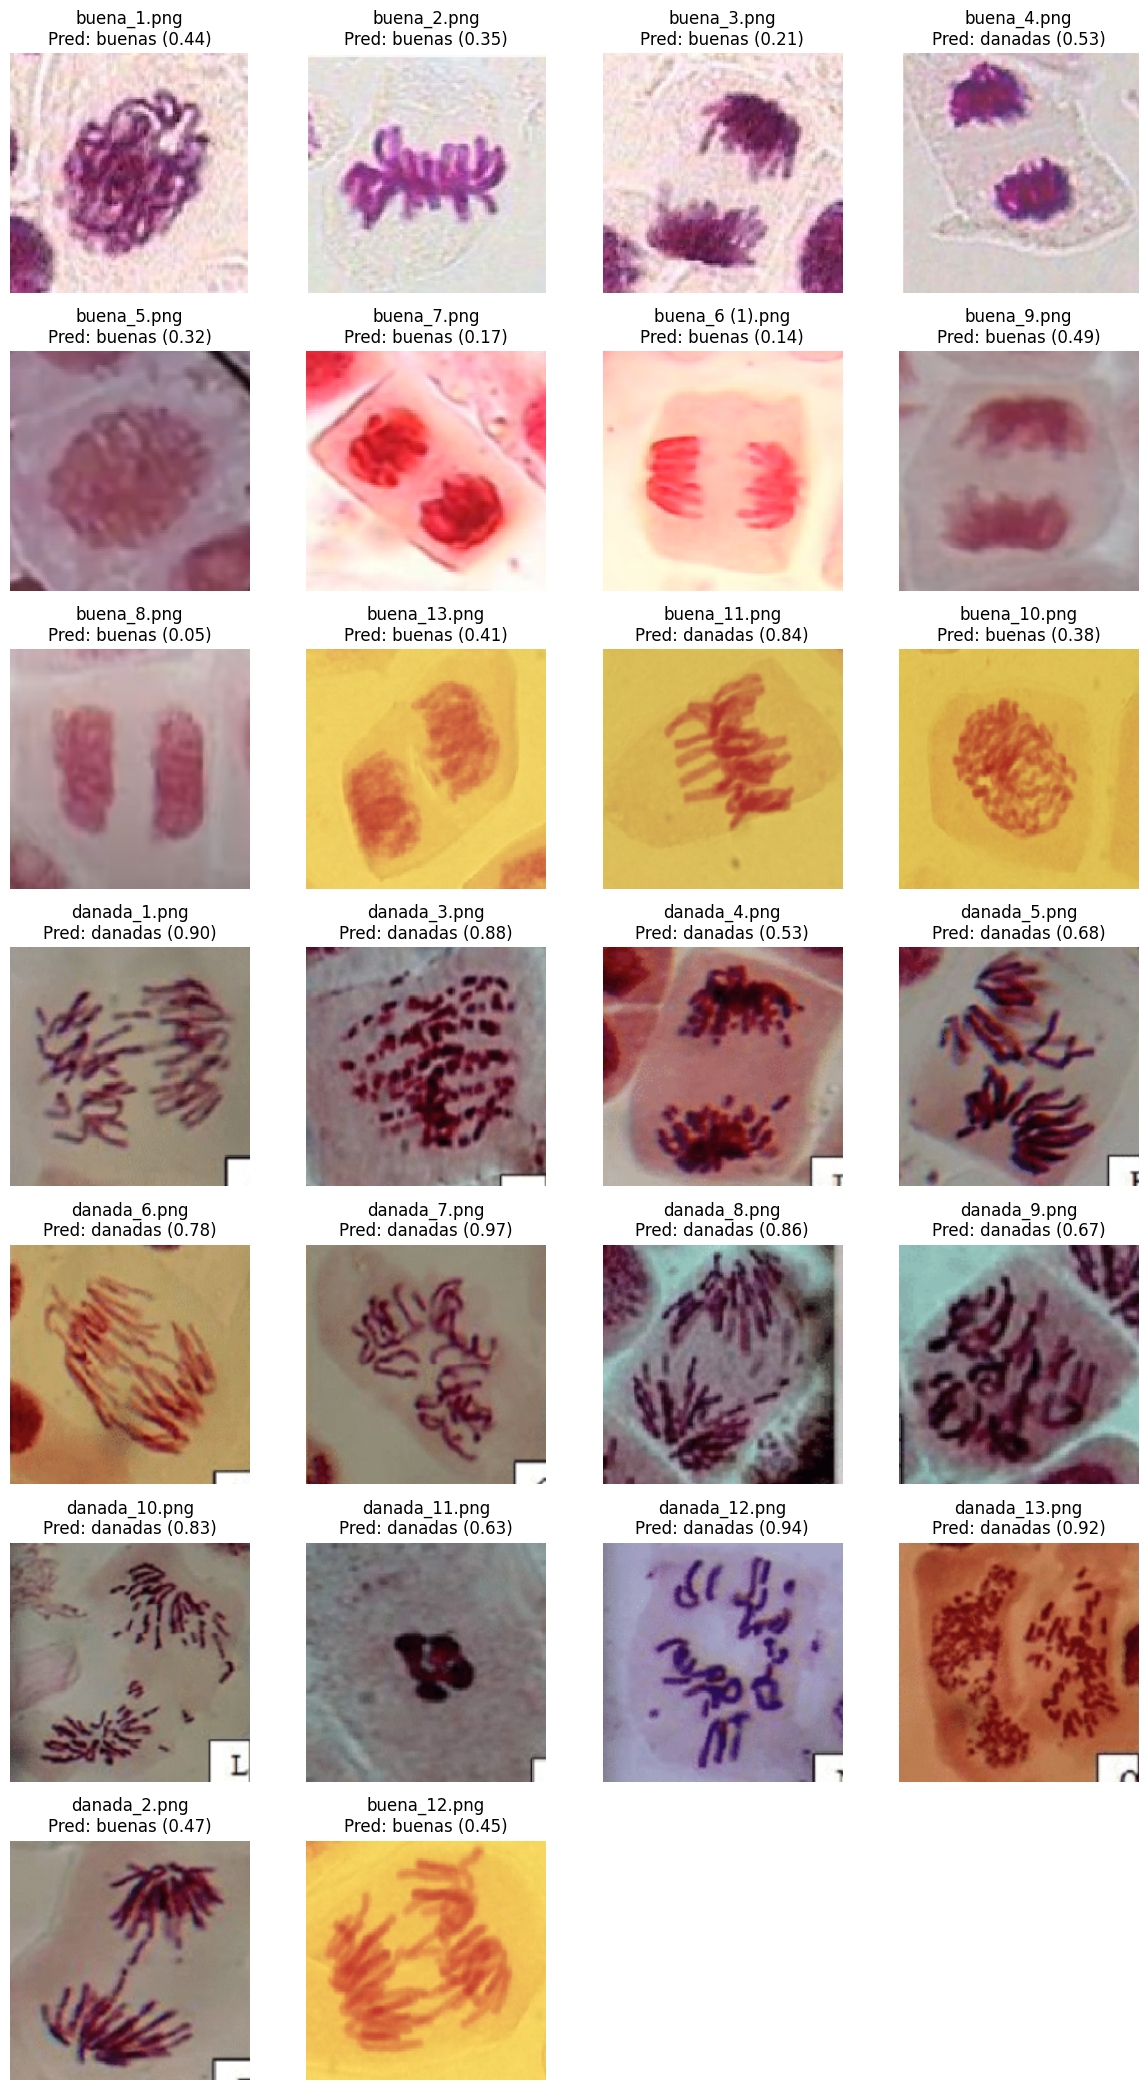

In [ ]:
import cv2
import os
import numpy as np
from google.colab import drive
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt


drive.mount('/content/drive')


rutas_imagenes = []
for nombre_archivo in os.listdir('/content/drive/MyDrive/test'):
    rutas_imagenes.append(os.path.join('/content/drive/MyDrive/test', nombre_archivo))


ruta_modelo = '/content/drive/MyDrive/Modelos/Mitosisv2.keras'
modelo = tf.keras.models.load_model(ruta_modelo)

def preprocesar_imagen(ruta_imagen):
    img = image.load_img(ruta_imagen, target_size=(224, 224))
    img = image.img_to_array(img)
    gaussiana = cv2.GaussianBlur(img, (5, 5), 0)
    imagen_procesada = np.expand_dims(gaussiana, axis=0)
    imagen_procesada /= 255.0
    return imagen_procesada


etiquetas_clases = {'buenas': 0, 'danadas': 1}


num_imagenes = len(rutas_imagenes)
columnas = 4
filas = (num_imagenes + columnas - 1) // columnas

plt.figure(figsize=(columnas * 3, filas * 3))

for i, ruta_imagen in enumerate(rutas_imagenes):
    imagen_procesada = preprocesar_imagen(ruta_imagen)
    prediccion = modelo.predict(imagen_procesada)
    indice_clase = int(np.round(prediccion[0][0]))
    etiqueta_predicha = list(etiquetas_clases.keys())[list(etiquetas_clases.values()).index(indice_clase)]
    probabilidad = prediccion[0][0]

    plt.subplot(filas, columnas, i + 1)
    plt.imshow(image.load_img(ruta_imagen, target_size=(224, 224)))
    plt.title(f"{os.path.basename(ruta_imagen)}\nPred: {etiqueta_predicha} ({probabilidad:.2f})")
    plt.axis('off')

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1

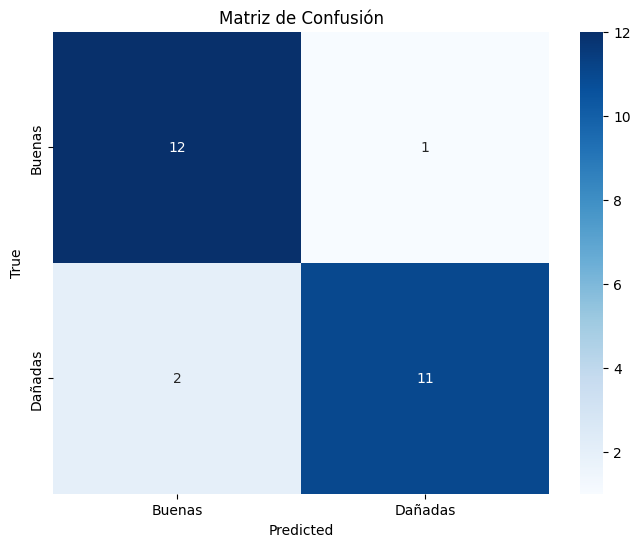

In [ ]:
import os
import cv2
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
import tensorflow as tf

directorio_prueba = '/content/drive/MyDrive/test'


ruta_modelo = '/content/drive/MyDrive/Modelos/Mitosis2clases90v2.keras'
modelo = tf.keras.models.load_model(ruta_modelo)


def preprocesar_imagen(ruta_imagen):
    img = image.load_img(ruta_imagen, target_size=(224, 224))
    img = image.img_to_array(img)
    gaussiana = cv2.GaussianBlur(img, (5, 5), 0)
    imagen_procesada = np.expand_dims(gaussiana, axis=0)
    imagen_procesada /= 255.0
    return imagen_procesada


etiquetas_reales = []
etiquetas_predichas = []


for nombre_archivo in os.listdir(directorio_prueba):
    if nombre_archivo.endswith(('.png', '.jpg', '.jpeg')):
        ruta_imagen = os.path.join(directorio_prueba, nombre_archivo)
        imagen = preprocesar_imagen(ruta_imagen)

        # realizar la predicion
        prediccion = modelo.predict(imagen)
        indice_predicho = int(np.round(prediccion[0][0]))

        if 'danada' in nombre_archivo:
            etiqueta_real = 1
        if 'buena' in nombre_archivo:
            etiqueta_real = 0


        etiquetas_reales.append(etiqueta_real)
        etiquetas_predichas.append(indice_predicho)


matriz_confusion = confusion_matrix(etiquetas_reales, etiquetas_predichas) # matriz de confusion


plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Buenas', 'Dañadas'],
            yticklabels=['Buenas', 'Dañadas'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Matriz de Confusion')
plt.show()
